# 7-2. 캘리브레이션 풀이 채점 origin을 따라 정말 늘어나는가

`5-1`/`6-1`/`6-3`의 `INITIAL_CALIB`/`MIN_TRAIN`이 origin을 나누는데, "채점이 뒤로 갈수록 캘리브레이션 풀이 늘어나는 구조인지" 코드 근거+실제 숫자로 확인한다.

- **근거**: `calib = g[g["origin"].isin(origins[:i])]`에서 `origins[:i]`는 i가 커질수록 원소가 느는 슬라이스 -- 고정폭 롤링이 아니라 **확장형(expanding window) 구조**다.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

H = 4
INITIAL_CALIB = 15
MIN_TRAIN = 20
TARGET_VAR = "X3_l1"
MODEL = "arima_aic"

err_42 = pd.read_pickle("../cache/cache_nb4_2_err_df.pkl")
g = err_42[(err_42["model"] == MODEL) & (err_42["var"] == TARGET_VAR)]
origins = sorted(g["origin"].unique())

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
quarters = raw[["quarter", TARGET_VAR]].dropna()["quarter"].values  # origin 인덱스와 동일하게 정렬됨

print(f"대표변수: {TARGET_VAR}, 대표모델: {MODEL}, 전체 origin {len(origins)}개(첫 채점 index={INITIAL_CALIB})")


대표변수: X3_l1, 대표모델: arima_aic, 전체 origin 37개(첫 채점 index=15)


## 1. `origins[:i]` 슬라이스를 그대로 재현해서 풀 크기 추적

`5-1`과 동일한 루프로, CRPS 대신 **그 시점 캘리브레이션 풀 자체**(크기, 시작/끝 origin)를 기록한다.


In [2]:
rows = []
for i in range(INITIAL_CALIB, len(origins)):
    calib_origins = origins[:i]
    scored_origin = origins[i]
    calib_df = g[g["origin"].isin(calib_origins)]
    actual_calib_origin_count = calib_df["origin"].nunique()
    rows.append({
        "채점순번(i)": i,
        "채점 origin": scored_origin,
        "채점 분기": quarters[scored_origin],
        "캘리브레이션 풀 크기(=i)": len(calib_origins),
        "실제 calib_df의 origin 개수": actual_calib_origin_count,
        "풀 시작 origin": calib_origins[0],
        "풀 시작 분기": quarters[calib_origins[0]],
        "풀 끝 origin": calib_origins[-1],
        "풀 끝 분기": quarters[calib_origins[-1]],
    })

pool_df = pd.DataFrame(rows)
display(pool_df)


,채점순번(i),채점 origin,채점 분기,캘리브레이션 풀 크기(=i),실제 calib_df의 origin 개수,풀 시작 origin,풀 시작 분기,풀 끝 origin,풀 끝 분기
0,15,35,2019Q4,15,15,20,2016Q1,34,2019Q3
1,16,36,2020Q1,16,16,20,2016Q1,35,2019Q4
2,17,37,2020Q2,17,17,20,2016Q1,36,2020Q1
3,18,38,2020Q3,18,18,20,2016Q1,37,2020Q2
4,19,39,2020Q4,19,19,20,2016Q1,38,2020Q3
5,20,40,2021Q1,20,20,20,2016Q1,39,2020Q4
6,21,41,2021Q2,21,21,20,2016Q1,40,2021Q1
7,22,42,2021Q3,22,22,20,2016Q1,41,2021Q2
8,23,43,2021Q4,23,23,20,2016Q1,42,2021Q3
9,24,44,2022Q1,24,24,20,2016Q1,43,2021Q4


In [3]:
always_matches = (pool_df["캘리브레이션 풀 크기(=i)"] == pool_df["실제 calib_df의 origin 개수"]).all()
strictly_increasing = pool_df["캘리브레이션 풀 크기(=i)"].is_monotonic_increasing and pool_df["캘리브레이션 풀 크기(=i)"].diff().dropna().eq(1).all()
end_reaches_last_available = pool_df["풀 끝 origin"].iloc[-1] == origins[-2]  # 마지막 채점 origin 바로 이전 origin까지 포함

print(f"풀 크기가 실제 데이터와 항상 일치: {always_matches}")
print(f"풀 크기가 채점마다 정확히 1씩 늘어남(확장형 확인): {strictly_increasing}")
print(f"마지막 채점 시점엔 채점 origin 바로 이전 origin까지 풀에 포함됨: {end_reaches_last_available}")
print(f"풀 크기 범위: {pool_df['캘리브레이션 풀 크기(=i)'].min()}개 -> {pool_df['캘리브레이션 풀 크기(=i)'].max()}개 (채점 origin {len(pool_df)}개에 걸쳐)")


풀 크기가 실제 데이터와 항상 일치: True
풀 크기가 채점마다 정확히 1씩 늘어남(확장형 확인): True
마지막 채점 시점엔 채점 origin 바로 이전 origin까지 풀에 포함됨: True
풀 크기 범위: 15개 -> 36개 (채점 origin 22개에 걸쳐)


## 2. 시각화 -- 채점 origin이 뒤로 갈수록 풀이 정말 끝까지 늘어나는가


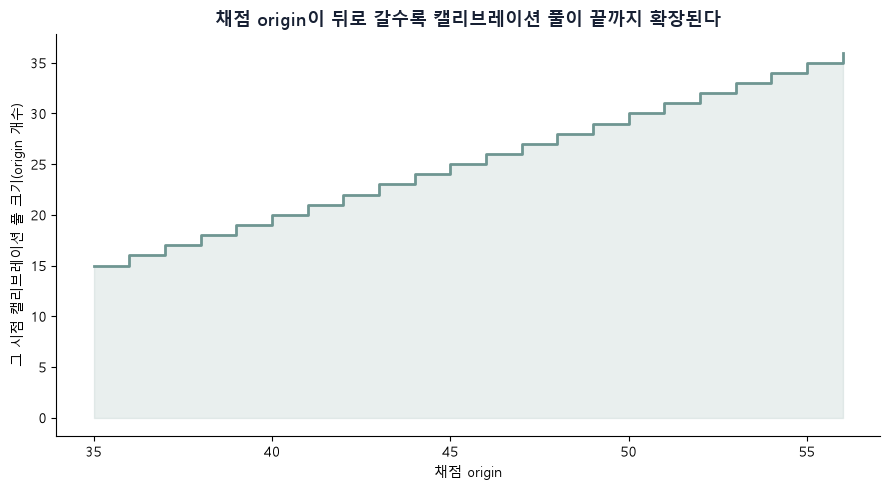

In [4]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(9, 5))
ax.step(pool_df["채점 origin"], pool_df["캘리브레이션 풀 크기(=i)"], where="post", color="#6F9692", linewidth=2)
ax.fill_between(pool_df["채점 origin"], pool_df["캘리브레이션 풀 크기(=i)"], step="post", color="#6F9692", alpha=0.15)
ax.set_xlabel("채점 origin")
ax.set_ylabel("그 시점 캘리브레이션 풀 크기(origin 개수)")
ax.set_title("채점 origin이 뒤로 갈수록 캘리브레이션 풀이 끝까지 확장된다", fontsize=13, fontweight="bold", color="#172033")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


## 2-1. 채점 시점 5개를 확대해서 보기 -- "채점"은 정확히 어디를 보나

채점 origin 하나는 그 시점부터 향후 4개 분기(h=1~4)를 평균해서 점수를 낸다. 5개 표본에서 그 4분기 구간(빨간색)과 캘리브레이션 풀(회색)만 표시하고, 나머지 채점 예정 구간은 옅은 색으로 남긴다.


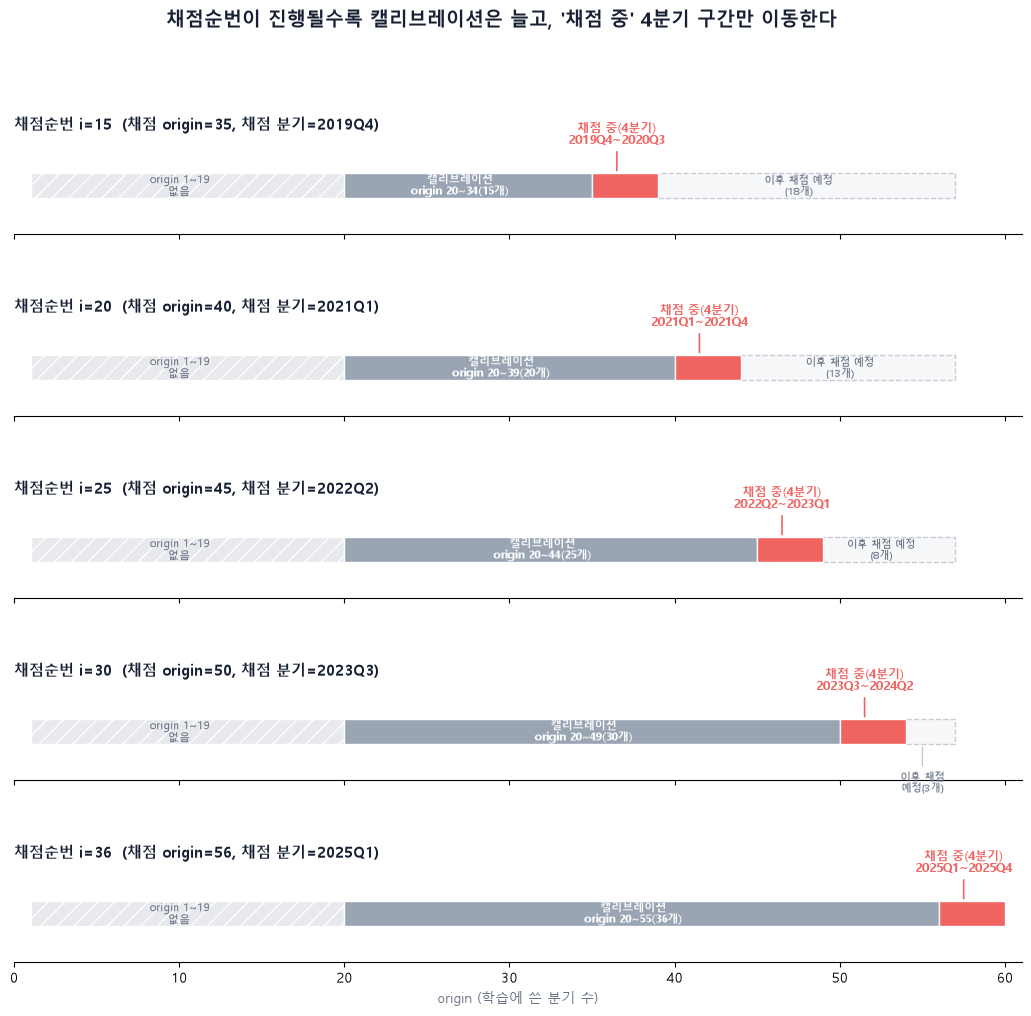

In [5]:
sample_idx = [INITIAL_CALIB, INITIAL_CALIB + (len(origins) - 1 - INITIAL_CALIB) // 4,
              INITIAL_CALIB + (len(origins) - 1 - INITIAL_CALIB) // 2,
              INITIAL_CALIB + 3 * (len(origins) - 1 - INITIAL_CALIB) // 4, len(origins) - 1]
N_LAST = origins[-1]

GRAY_NONE, BLUEGRAY_CALIB, CORAL_SCORE, PALE_FUTURE = "#E8E9EC", "#9AA5B4", "#EF6461", "#F7F8FA"
LABEL_COLOR, NAVY = "#697386", "#172033"

fig, axes = plt.subplots(len(sample_idx), 1, figsize=(13, 1.9 * len(sample_idx) + 1.2), sharex=True,
                          gridspec_kw={"hspace": 0.9})

for ax, i in zip(axes, sample_idx):
    o = origins[i]
    calib_start, calib_end = MIN_TRAIN, o - 1
    score_start, score_end = o, o + H - 1
    future_start, future_end = o + H, N_LAST

    ax.barh(0, MIN_TRAIN - 1, left=1, height=0.6, color=GRAY_NONE, edgecolor="white", hatch="//")
    ax.text(MIN_TRAIN / 2, 0, f"origin 1~{MIN_TRAIN - 1}\n없음", ha="center", va="center", fontsize=8, color=LABEL_COLOR)

    calib_n = calib_end - calib_start + 1
    ax.barh(0, calib_n, left=calib_start, height=0.6, color=BLUEGRAY_CALIB, edgecolor="white")
    ax.text((calib_start + calib_end) / 2, 0, f"캘리브레이션\norigin {calib_start}~{calib_end}({calib_n}개)",
            ha="center", va="center", fontsize=8, color="white", fontweight="bold")

    score_mid = (score_start + score_end) / 2
    ax.barh(0, H, left=score_start, height=0.6, color=CORAL_SCORE, edgecolor="white", zorder=3)
    q_label = f"{quarters[score_start]}~{quarters[score_end]}"
    ax.annotate(f"채점 중(4분기)\n{q_label}", xy=(score_mid, 0.3), xytext=(score_mid, 0.95),
                ha="center", va="bottom", fontsize=8.5, color=CORAL_SCORE, fontweight="bold",
                arrowprops=dict(arrowstyle="-", color=CORAL_SCORE, lw=1.2))

    if future_end >= future_start:
        future_n = future_end - future_start + 1
        ax.barh(0, future_n, left=future_start, height=0.6, facecolor=PALE_FUTURE, edgecolor="#C7CBD3", linestyle="--")
        if future_n >= 5:
            ax.text((future_start + future_end) / 2, 0, f"이후 채점 예정\n({future_n}개)",
                    ha="center", va="center", fontsize=7.5, color=LABEL_COLOR)
        else:
            ax.annotate(f"이후 채점\n예정({future_n}개)", xy=((future_start + future_end) / 2, -0.3),
                        xytext=((future_start + future_end) / 2, -0.95),
                        ha="center", va="top", fontsize=7.5, color=LABEL_COLOR,
                        arrowprops=dict(arrowstyle="-", color="#C7CBD3", lw=1))

    ax.set_ylim(-1.15, 1.15)
    ax.set_yticks([])
    ax.set_xlim(0, N_LAST + H + 1)
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.set_title(f"채점순번 i={i}  (채점 origin={o}, 채점 분기={quarters[o]})", loc="left", fontsize=10.5, fontweight="bold", color=NAVY, pad=6)

axes[-1].set_xlabel("origin (학습에 쓴 분기 수)", fontsize=10, color=LABEL_COLOR)
fig.suptitle("채점순번이 진행될수록 캘리브레이션은 늘고, '채점 중' 4분기 구간만 이동한다", fontsize=13.5, fontweight="bold", color=NAVY, y=1.0)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


## 3. 결론

- **확장형(expanding window) 구조 맞음** -- 채점마다 풀이 정확히 1개씩 늘고(계단식 우상향), 마지막 채점 시점엔 직전 origin까지 전부 포함.
- 고정폭 롤링이 아니라 매번 과거 전체를 쓰므로, origin이 늘수록 표본부족 문제가 자연히 완화됨.
- **수정 불필요**: `INITIAL_CALIB=15`는 채점 시작점일 뿐, 풀 자체는 거기서 멈추지 않는다.
